**Nama:** Faishal Rabbani  
**NPM:** 25083010024  
**Kelas:** A083  
**Mata Kuliah:** Analisis Numerik

Link Gifthub :


## Deskripsi

Analisis ini menggunakan data laba/rugi harian dari lima gerai donat dengan strategi marketing yang berbeda.

Analisis yang dilakukan meliputi:

1. Membuat plot jumlah penjualan terhadap revenue.
2. Menerapkan regresi untuk mengetahui tren revenue berdasarkan volume penjualan.
3. Mencari jumlah penjualan yang menghasilkan Break Even Point (BEP) menggunakan metode pencarian akar.

Metode regresi yang digunakan adalah regresi linear, sedangkan metode pencarian akar yang digunakan adalah metode Bisection.

## 1. Import Library

Library yang digunakan adalah `pandas` untuk pengolahan data, `numpy` untuk perhitungan numerik, dan `matplotlib` untuk visualisasi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Membaca Dataset

Dataset berisi data harian dari lima gerai donat, yaitu Gerai A, B, C, D, dan E.

In [2]:
url = "https://raw.githubusercontent.com/jendralhxr/metnummatdis/main/sintesis_data_donat_harian.csv"

df = pd.read_csv(url)

df.head()

,Tanggal,Gerai,Harga Jual (Rp),Jumlah Terjual (Unit),Pendapatan Kotor (Rp),Biaya Variabel (Rp),Fixed Cost Harian (Rp),Balance (Rp)
0,2026-01-01,Gerai A,25000,87,2175000,739500,1683333,-247833
1,2026-01-02,Gerai A,25000,81,2025000,688500,1683333,-346833
2,2026-01-03,Gerai A,25000,110,2750000,935000,1683333,131667
3,2026-01-04,Gerai A,25000,119,2975000,1011500,1683333,280167
4,2026-01-05,Gerai A,25000,94,2350000,799000,1683333,-132333


In [3]:
df.shape

(450, 8)

In [4]:
df.columns

Index(['Tanggal', 'Gerai', 'Harga Jual (Rp)', 'Jumlah Terjual (Unit)',
       'Pendapatan Kotor (Rp)', 'Biaya Variabel (Rp)',
       'Fixed Cost Harian (Rp)', 'Balance (Rp)'],
      dtype='object')

Dataset kemudian diperiksa untuk memastikan tidak terdapat data kosong yang dapat mengganggu proses analisis.

In [5]:
df.isnull().sum()

,0
Tanggal,0
Gerai,0
Harga Jual (Rp),0
Jumlah Terjual (Unit),0
Pendapatan Kotor (Rp),0
Biaya Variabel (Rp),0
Fixed Cost Harian (Rp),0
Balance (Rp),0


## 3. Plot Jumlah Penjualan vs Revenue

Plot digunakan untuk melihat hubungan antara jumlah produk yang terjual dengan revenue pada masing-masing gerai.

- Sumbu X = jumlah penjualan
- Sumbu Y = revenue atau pendapatan kotor

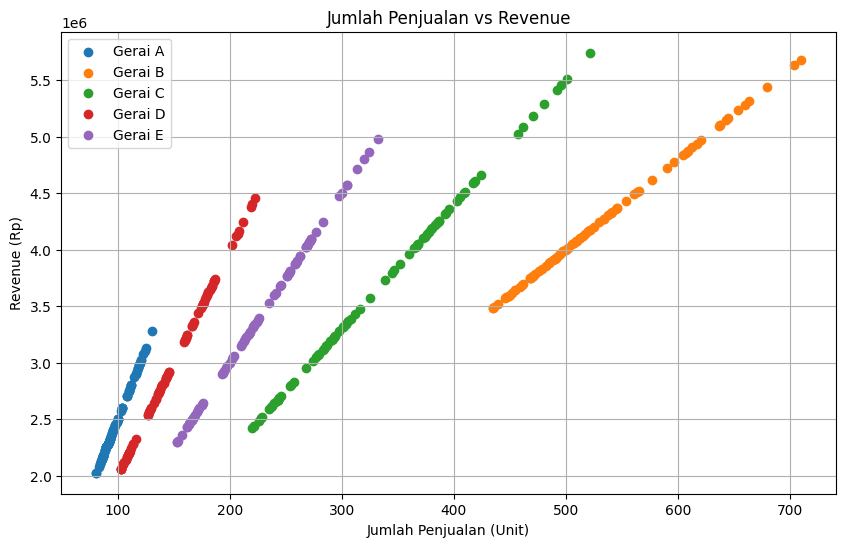

In [6]:
plt.figure(figsize=(10, 6))

for gerai in df["Gerai"].unique():
    data = df[df["Gerai"] == gerai]

    plt.scatter(
        data["Jumlah Terjual (Unit)"],
        data["Pendapatan Kotor (Rp)"],
        label=gerai
    )

plt.xlabel("Jumlah Penjualan (Unit)")
plt.ylabel("Revenue (Rp)")
plt.title("Jumlah Penjualan vs Revenue")
plt.legend()
plt.grid(True)
plt.show()

### Interpretasi

Berdasarkan plot, terlihat bahwa peningkatan jumlah penjualan diikuti dengan peningkatan revenue. Hubungan tersebut terlihat mendekati linear pada masing-masing gerai.

## 4. Regresi Linear

Regresi linear digunakan untuk mengetahui hubungan antara jumlah penjualan dengan revenue.

Model regresi linear:

$$
y = a + bx
$$

dengan:

- $x$ = jumlah penjualan
- $y$ = revenue
- $a$ = intercept
- $b$ = slope

### Rumus Regresi Linear

Koefisien regresi dihitung menggunakan metode Least Squares.

$$
b =
\frac{n\sum xy-\sum x\sum y}
{n\sum x^2-(\sum x)^2}
$$

Kemudian nilai intercept dihitung dengan:

$$
a = \bar{y}-b\bar{x}
$$

In [7]:
def regresi_linear(x, y):
    n = len(x)

    b = (
        n * np.sum(x * y) - np.sum(x) * np.sum(y)
    ) / (
        n * np.sum(x**2) - np.sum(x)**2
    )

    a = np.mean(y) - b * np.mean(x)

    return a, b

### Regresi Revenue Setiap Gerai

Regresi dilakukan secara terpisah untuk masing-masing gerai.

In [8]:
hasil_regresi = []

for gerai in df["Gerai"].unique():

    data = df[df["Gerai"] == gerai]

    x = data["Jumlah Terjual (Unit)"].values
    y = data["Pendapatan Kotor (Rp)"].values

    a, b = regresi_linear(x, y)

    hasil_regresi.append([
        gerai,
        a,
        b
    ])

regresi_df = pd.DataFrame(
    hasil_regresi,
    columns=["Gerai", "Intercept", "Slope"]
)

regresi_df

,Gerai,Intercept,Slope
0,Gerai A,0.000000e+00,25000.0
1,Gerai B,0.000000e+00,8000.0
2,Gerai C,0.000000e+00,11000.0
3,Gerai D,-4.656613e-10,20000.0
4,Gerai E,0.000000e+00,15000.0


### Persamaan Regresi

Persamaan regresi masing-masing gerai dapat dinyatakan dalam bentuk:

$$
Revenue = a + bx
$$

Nilai $b$ menunjukkan perubahan revenue untuk setiap tambahan satu unit penjualan.

In [9]:
for _, row in regresi_df.iterrows():
    print(
        f"{row['Gerai']}: "
        f"Revenue = {row['Intercept']:.2f} + "
        f"{row['Slope']:.2f}X"
    )

Gerai A: Revenue = 0.00 + 25000.00X
Gerai B: Revenue = 0.00 + 8000.00X
Gerai C: Revenue = 0.00 + 11000.00X
Gerai D: Revenue = -0.00 + 20000.00X
Gerai E: Revenue = 0.00 + 15000.00X


### Visualisasi Regresi

Garis regresi ditambahkan ke dalam scatter plot untuk melihat bentuk tren revenue terhadap volume penjualan.

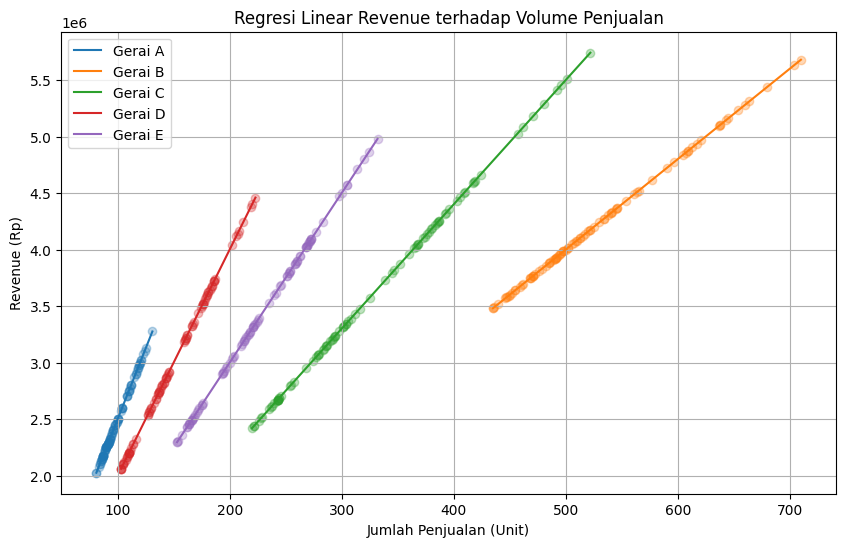

In [10]:
plt.figure(figsize=(10, 6))

for gerai in df["Gerai"].unique():

    data = df[df["Gerai"] == gerai]

    x = data["Jumlah Terjual (Unit)"].values
    y = data["Pendapatan Kotor (Rp)"].values

    a, b = regresi_linear(x, y)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = a + b * x_line

    plt.scatter(x, y, alpha=0.3)
    plt.plot(
        x_line,
        y_line,
        label=gerai
    )

plt.xlabel("Jumlah Penjualan (Unit)")
plt.ylabel("Revenue (Rp)")
plt.title("Regresi Linear Revenue terhadap Volume Penjualan")
plt.legend()
plt.grid(True)
plt.show()

## 5. Regresi Balance untuk Menentukan BEP

Break Even Point (BEP) terjadi ketika laba/rugi atau `Balance` bernilai nol.

Dengan demikian:

$$
Balance = 0
$$

Untuk mencari jumlah penjualan pada kondisi tersebut, dilakukan regresi antara jumlah penjualan dengan Balance.

Model yang digunakan:

$$
Balance = a + bx
$$

Kemudian akar persamaan tersebut dicari menggunakan metode Bisection.

In [11]:
hasil_balance = []

for gerai in df["Gerai"].unique():

    data = df[df["Gerai"] == gerai]

    x = data["Jumlah Terjual (Unit)"].values
    y = data["Balance (Rp)"].values

    a, b = regresi_linear(x, y)

    hasil_balance.append([
        gerai,
        a,
        b
    ])

balance_df = pd.DataFrame(
    hasil_balance,
    columns=["Gerai", "Intercept", "Slope"]
)

balance_df

,Gerai,Intercept,Slope
0,Gerai A,-1683333.0,16500.0
1,Gerai B,-733333.0,3840.0
2,Gerai C,-1733333.0,6160.0
3,Gerai D,-2666666.0,12800.0
4,Gerai E,-800000.0,8700.0


## 6. Metode Bisection

Metode Bisection digunakan untuk mencari akar dari fungsi.

Pada analisis ini:

$$
f(x) = a + bx
$$

Akar dicari ketika:

$$
f(x) = 0
$$

Karena kondisi tersebut sama dengan `Balance = 0`, maka akar yang diperoleh merupakan jumlah penjualan pada Break Even Point.

In [12]:
def bisection(f, a, b, tol=0.001, max_iter=100):

    fa = f(a)
    fb = f(b)

    if fa * fb > 0:
        return None

    for i in range(max_iter):

        c = (a + b) / 2
        fc = f(c)

        if abs(fc) < tol:
            return c

        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c

## 7. Perhitungan BEP Masing-Masing Gerai

Setiap persamaan regresi Balance digunakan sebagai fungsi untuk metode Bisection.

Interval pencarian dimulai dari 0 sampai dua kali jumlah penjualan maksimum pada masing-masing gerai.

In [13]:
hasil_bep = []

for gerai in df["Gerai"].unique():

    data = df[df["Gerai"] == gerai]

    x = data["Jumlah Terjual (Unit)"].values
    y = data["Balance (Rp)"].values

    a, b = regresi_linear(x, y)

    fungsi = lambda x, a=a, b=b: a + b * x

    batas_bawah = 0
    batas_atas = max(x) * 2

    bep = bisection(
        fungsi,
        batas_bawah,
        batas_atas
    )

    hasil_bep.append([
        gerai,
        a,
        b,
        bep,
        np.ceil(bep)
    ])

bep_df = pd.DataFrame(
    hasil_bep,
    columns=[
        "Gerai",
        "Intercept",
        "Slope",
        "BEP",
        "BEP Dibulatkan"
    ]
)

bep_df

,Gerai,Intercept,Slope,BEP,BEP Dibulatkan
0,Gerai A,-1683333.0,16500.0,102.020182,103.0
1,Gerai B,-733333.0,3840.0,190.972136,191.0
2,Gerai C,-1733333.0,6160.0,281.385227,282.0
3,Gerai D,-2666666.0,12800.0,208.333281,209.0
4,Gerai E,-800000.0,8700.0,91.954023,92.0


## 8. Hasil Break Even Point

Nilai BEP menunjukkan perkiraan jumlah donat yang harus terjual dalam satu hari agar Balance mencapai nol.

Karena jumlah donat yang terjual harus berupa bilangan bulat, maka nilai BEP dibulatkan ke atas.

In [14]:
bep_df[
    ["Gerai", "BEP", "BEP Dibulatkan"]
]

,Gerai,BEP,BEP Dibulatkan
0,Gerai A,102.020182,103.0
1,Gerai B,190.972136,191.0
2,Gerai C,281.385227,282.0
3,Gerai D,208.333281,209.0
4,Gerai E,91.954023,92.0


## 9. Visualisasi BEP

Grafik berikut menunjukkan hubungan antara jumlah penjualan dan Balance. Garis horizontal pada $Balance = 0$ menunjukkan kondisi Break Even Point.

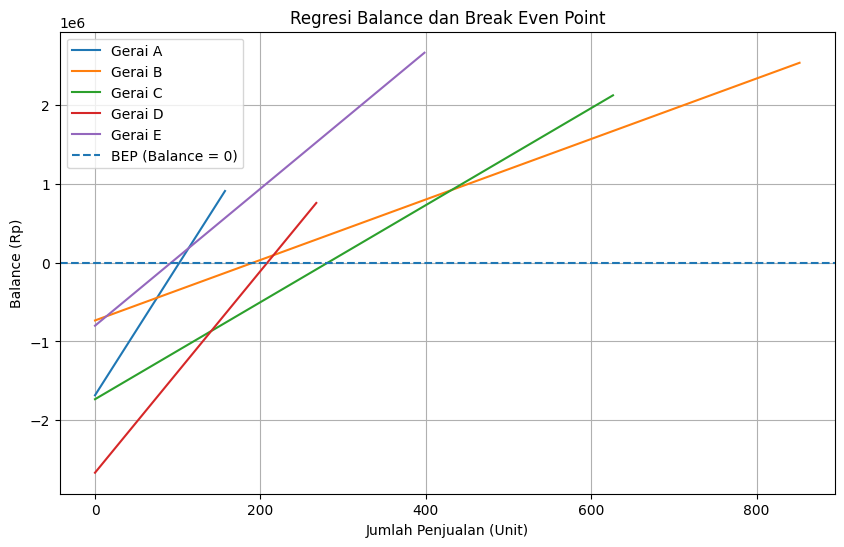

In [15]:
plt.figure(figsize=(10, 6))

for gerai in df["Gerai"].unique():

    data = df[df["Gerai"] == gerai]

    x = data["Jumlah Terjual (Unit)"].values
    y = data["Balance (Rp)"].values

    a, b = regresi_linear(x, y)

    x_line = np.linspace(
        0,
        max(x) * 1.2,
        100
    )

    y_line = a + b * x_line

    plt.plot(
        x_line,
        y_line,
        label=gerai
    )

plt.axhline(
    0,
    linestyle="--",
    label="BEP (Balance = 0)"
)

plt.xlabel("Jumlah Penjualan (Unit)")
plt.ylabel("Balance (Rp)")
plt.title("Regresi Balance dan Break Even Point")
plt.legend()
plt.grid(True)
plt.show()

# 10. Kesimpulan

Berdasarkan hasil analisis, jumlah penjualan memiliki hubungan linear dengan revenue pada kelima gerai donat. Regresi linear digunakan untuk memperoleh persamaan yang menggambarkan hubungan antara volume penjualan dan revenue.

Selanjutnya, regresi dilakukan terhadap variabel Balance untuk memperoleh fungsi yang digunakan dalam pencarian Break Even Point. Metode Bisection digunakan untuk mencari akar dari fungsi tersebut, yaitu ketika Balance = 0.

Nilai akar yang diperoleh menunjukkan jumlah penjualan yang diperlukan oleh masing-masing gerai untuk mencapai kondisi impas. Nilai tersebut kemudian dibulatkan ke atas karena jumlah produk yang dijual harus berupa bilangan bulat.

Dengan demikian, analisis telah mencakup dua metode numerik utama, yaitu **regresi linear** dan **pencarian akar menggunakan metode Bisection**, sesuai dengan tujuan tugas Analisis Numerik.